# ¿Funcionan los anuncios? Análisis de un A/B test de marketing

**Pregunta de negocio:** una empresa lanza una campaña de anuncios y quiere saber dos cosas:

1. ¿La campaña aumenta las compras?
2. Si es así, ¿cuántas compras se deben de verdad a los anuncios y cuánto se puede pagar por ellos?

**Diseño del experimento:** 588.101 usuarios repartidos al azar en dos grupos. El grupo **anuncios** (96 %) ve el anuncio de la campaña. El grupo **control** (4 %) ve en el mismo hueco un anuncio de servicio público (PSA), así que los dos grupos ven el mismo número de impresiones y solo cambia el contenido.

**Métrica principal:** tasa de conversión (el usuario compra el producto).

Datos: [Marketing A/B Testing](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) (Kaggle, CC0).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from ab.datos import cargar, descargar, efecto_por_segmento, grupos
from ab.estadistica import (bayes_beta_binomial, bootstrap_diferencia, efecto_minimo_detectable,
                            potencia, prueba_z, tamano_muestral)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold"})
AZUL, GRIS, ROJO = "#1a56db", "#9ca3af", "#dc2626"
IMG = "docs/img/"

descargar()
df = cargar()
df.head()

,usuario,grupo,convertido,impresiones,dia_max,hora_max,tramo_impresiones,franja_horaria
0,1069124,anuncios,0,130,lunes,20,100-199,noche (18-23 h)
1,1119715,anuncios,0,93,martes,22,50-99,noche (18-23 h)
2,1144181,anuncios,0,21,martes,18,10-24,noche (18-23 h)
3,1435133,anuncios,0,355,martes,10,200 o más,mañana (6-11 h)
4,1015700,anuncios,0,276,viernes,14,200 o más,tarde (12-17 h)


## 1. Calidad de los datos

In [2]:
print(f"Filas: {len(df):,}  |  usuarios únicos: {df['usuario'].nunique():,}  |  nulos: {df.isna().sum().sum()}")
df.groupby("grupo").agg(
    usuarios=("usuario", "size"),
    conversiones=("convertido", "sum"),
    tasa_conversion=("convertido", "mean"),
    impresiones_media=("impresiones", "mean"),
    impresiones_mediana=("impresiones", "median"),
)

Filas: 588,101  |  usuarios únicos: 588,101  |  nulos: 0


,usuarios,conversiones,tasa_conversion,impresiones_media,impresiones_mediana
grupo,,,,,
anuncios,564577,14423,0.0255,24.8234,13.0000
control,23524,420,0.0179,24.7611,12.0000


Un usuario por fila, sin duplicados ni nulos. Las impresiones tienen una cola muy larga (la mediana es 13 y hay usuarios con más de 2.000), así que más adelante las agrupo en tramos.

## 2. ¿El reparto fue de verdad al azar?

Antes de mirar el resultado compruebo que los dos grupos son comparables. Si la asignación fue aleatoria, las variables que no dependen del anuncio deberían repartirse igual en los dos grupos:

- **Impresiones:** los dos grupos ocupan el mismo hueco, así que el número de impresiones mide lo activo que es el usuario, no el efecto del anuncio.
- **Día y hora** con más impresiones.

No puedo hacer el test clásico de *Sample Ratio Mismatch* porque el dataset no dice qué reparto se planificó (96/4 es lo observado, no necesariamente lo diseñado).

In [3]:
ctrl = df[df["grupo"] == "control"]
anun = df[df["grupo"] == "anuncios"]
balance = pd.DataFrame({
    "variable": ["impresiones (Kolmogorov-Smirnov)", "día con más impresiones (chi²)", "hora con más impresiones (chi²)"],
    "p_valor": [
        stats.ks_2samp(ctrl["impresiones"], anun["impresiones"]).pvalue,
        stats.chi2_contingency(pd.crosstab(df["grupo"], df["dia_max"])).pvalue,
        stats.chi2_contingency(pd.crosstab(df["grupo"], df["hora_max"])).pvalue,
    ],
})
balance

,variable,p_valor
0,impresiones (Kolmogorov-Smirnov),0.0000
1,día con más impresiones (chi²),0.0000
2,hora con más impresiones (chi²),0.0000


In [4]:
pd.concat({
    "impresiones": pd.crosstab(df["tramo_impresiones"], df["grupo"], normalize="columns"),
    "día": pd.crosstab(df["dia_max"], df["grupo"], normalize="columns"),
}).round(3)

grupo                  anuncios  control
impresiones 1-9          0.4220   0.4610
            10-24        0.2960   0.2620
            25-49        0.1620   0.1520
            50-99        0.0810   0.0810
            100-199      0.0300   0.0330
            200 o más    0.0100   0.0110
día         lunes        0.1480   0.1490
            martes       0.1320   0.1240
            miércoles    0.1370   0.1480
            jueves       0.1400   0.1660
            viernes      0.1570   0.1620
            sábado       0.1400   0.1210
            domingo      0.1460   0.1300

**Los grupos no están perfectamente equilibrados.** Con 588.000 usuarios cualquier diferencia sale significativa, así que lo importante es su tamaño:

- En el control hay algo más de usuarios con muy pocas impresiones (46 % con 1-9 frente a 42 %). Esos usuarios casi nunca compran, así que este desequilibrio, si acaso, **rebaja** la conversión del control y podría inflar un poco el efecto.
- El control tiene más usuarios cuyo día fuerte es el jueves (16,6 % frente a 14,0 %).

Puede deberse a cómo se hizo la asignación (el dataset no lo explica). No invalida el experimento, pero obliga a comprobar que el resultado **se mantiene al ajustar por estas variables** (apartado 3).

## 3. Resultado principal

In [5]:
a, b = grupos(df)
r = prueba_z(a, b)
print(f"Conversión control:  {r.tasa_a:.3%}  ({a.conversiones:,} de {a.n:,})")
print(f"Conversión anuncios: {r.tasa_b:.3%}  ({b.conversiones:,} de {b.n:,})")
print(f"Diferencia: +{100*r.diferencia:.2f} puntos  (IC 95 %: {100*r.ic_diferencia[0]:.2f} a {100*r.ic_diferencia[1]:.2f})")
print(f"Lift relativo: +{r.lift:.1%}  (IC 95 %: {r.ic_lift[0]:.1%} a {r.ic_lift[1]:.1%})")
print(f"z = {r.z:.2f}   p-valor = {r.p_valor:.1e}")

Conversión control:  1.785%  (420 de 23,524)
Conversión anuncios: 2.555%  (14,423 de 564,577)
Diferencia: +0.77 puntos  (IC 95 %: 0.60 a 0.94)
Lift relativo: +43.1%  (IC 95 %: 30.0% a 57.5%)
z = 7.37   p-valor = 1.7e-13


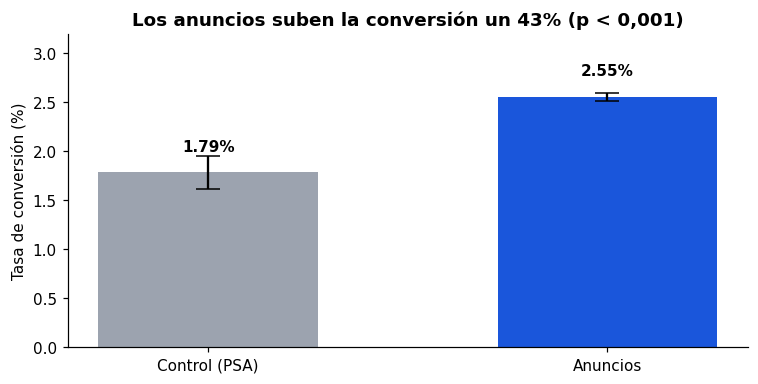

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
tasas = [r.tasa_a, r.tasa_b]
errores = [1.96 * np.sqrt(g.tasa * (1 - g.tasa) / g.n) for g in (a, b)]
ax.bar(["Control (PSA)", "Anuncios"], [100 * t for t in tasas], color=[GRIS, AZUL],
       yerr=[100 * e for e in errores], capsize=8, width=0.55)
for i, t in enumerate(tasas):
    ax.text(i, 100 * t + 0.22, f"{t:.2%}", ha="center", fontweight="bold")
ax.set_ylabel("Tasa de conversión (%)")
ax.set_ylim(0, 3.2)
ax.set_title(f"Los anuncios suben la conversión un {r.lift:.0%} (p < 0,001)")
fig.tight_layout(); fig.savefig(IMG + "conversion.png"); plt.show()

**Los anuncios funcionan:** la conversión pasa de 1,79 % a 2,55 %, +0,77 puntos, un **43 % más**. El intervalo de confianza va de +30 % a +58 %: aun en el peor caso razonable el efecto es grande. Con p ≈ 2·10⁻¹³ no es casualidad.

### Comprobación con otros dos métodos

- **Bootstrap:** no asume normalidad; remuestrea usuarios.
- **Bayesiano (Beta-Binomial):** responde a la pregunta que suele hacer negocio, «¿qué probabilidad hay de que los anuncios sean mejores?».

In [7]:
bajo, alto = bootstrap_diferencia(ctrl["convertido"].to_numpy(), anun["convertido"].to_numpy())
bay = bayes_beta_binomial(a, b)
pd.DataFrame({
    "método": ["z (Wald)", "bootstrap (5.000 remuestras)", "bayesiano (previa uniforme)"],
    "diferencia_pp_baja": [100 * r.ic_diferencia[0], 100 * bajo, np.nan],
    "diferencia_pp_alta": [100 * r.ic_diferencia[1], 100 * alto, np.nan],
    "lift_bajo": [r.ic_lift[0], np.nan, bay.ic_lift[0]],
    "lift_alto": [r.ic_lift[1], np.nan, bay.ic_lift[1]],
}).round(4), f"P(anuncios > control) = {bay.prob_b_mejor:.4f}"

(                         método  diferencia_pp_baja  diferencia_pp_alta  \
 0                      z (Wald)              0.5951              0.9434   
 1  bootstrap (5.000 remuestras)              0.5958              0.9439   
 2   bayesiano (previa uniforme)                 NaN                 NaN   
 
    lift_bajo  lift_alto  
 0     0.2997     0.5752  
 1        NaN        NaN  
 2     0.2995     0.5750  ,
 'P(anuncios > control) = 1.0000')

Los tres métodos coinciden: intervalo de +0,60 a +0,94 puntos y lift de +30 % a +58 %. La probabilidad bayesiana de que los anuncios sean mejores es prácticamente del 100 %.

### ¿Se mantiene al corregir el desequilibrio de los grupos?

Dos ajustes:

- **Estandarización:** comparo los grupos dentro de cada combinación de tramo de impresiones y día, y promedio las diferencias con el peso de cada combinación.
- **Regresión logística** con el grupo y las variables de control (impresiones, día y franja horaria).

In [8]:
import statsmodels.formula.api as smf

df["estrato"] = df["tramo_impresiones"].astype(str) + " | " + df["dia_max"].astype(str)
por_estrato = df.groupby(["estrato", "grupo"], observed=True)["convertido"].mean().unstack()
pesos = df.loc[df["grupo"] == "anuncios", "estrato"].value_counts(normalize=True)
dif_ajustada = ((por_estrato["anuncios"] - por_estrato["control"]) * pesos).sum()

formula = "convertido ~ C(grupo, Treatment('control'))"
bruto = smf.logit(formula, data=df).fit(disp=0)
ajustado = smf.logit(formula + " + C(tramo_impresiones) + C(dia_max) + C(franja_horaria)", data=df).fit(disp=0)
coef = [c for c in ajustado.params.index if "grupo" in c][0]
ic_or = np.exp(ajustado.conf_int().loc[coef])
pd.DataFrame({
    "estimación": ["diferencia bruta (pp)", "diferencia estandarizada por estrato (pp)",
                   "odds ratio bruto", "odds ratio ajustado (logística)"],
    "valor": [100 * r.diferencia, 100 * dif_ajustada, np.exp(bruto.params[coef]), np.exp(ajustado.params[coef])],
    "ic_95": ["0,60 a 0,94", "", "", f"{ic_or.iloc[0]:.2f} a {ic_or.iloc[1]:.2f}"],
}).round(3)

,estimación,valor,ic_95
0,diferencia bruta (pp),0.7690,"0,60 a 0,94"
1,diferencia estandarizada por estrato (pp),0.7640,
2,odds ratio bruto,1.4420,
3,odds ratio ajustado (logística),1.4800,1.34 a 1.64


El efecto ajustado es prácticamente igual que el bruto (+0,76 frente a +0,77 puntos; odds ratio de 1,48 frente a 1,44). **El desequilibrio no explica el resultado.**

## 4. ¿Estaba bien dimensionado el experimento?

Con un 4 % en control, el grupo de control tiene 23.524 usuarios. ¿Qué efecto mínimo se podía detectar?

In [9]:
mde = efecto_minimo_detectable(a.tasa, a.n, b.n)
print(f"Efecto mínimo detectable (80 % de potencia): +{100*mde:.2f} puntos ({mde / a.tasa:.0%} relativo)")
print(f"Potencia para el efecto observado: {potencia(a.tasa, r.diferencia, a.n, b.n):.4f}")
n50 = tamano_muestral(a.tasa, r.diferencia)
print(f"Con un reparto 50/50 habrían bastado {n50[0]:,} usuarios por grupo ({sum(n50):,} en total)")

Efecto mínimo detectable (80 % de potencia): +0.25 puntos (14% relativo)
Potencia para el efecto observado: 1.0000
Con un reparto 50/50 habrían bastado 5,628 usuarios por grupo (11,256 en total)


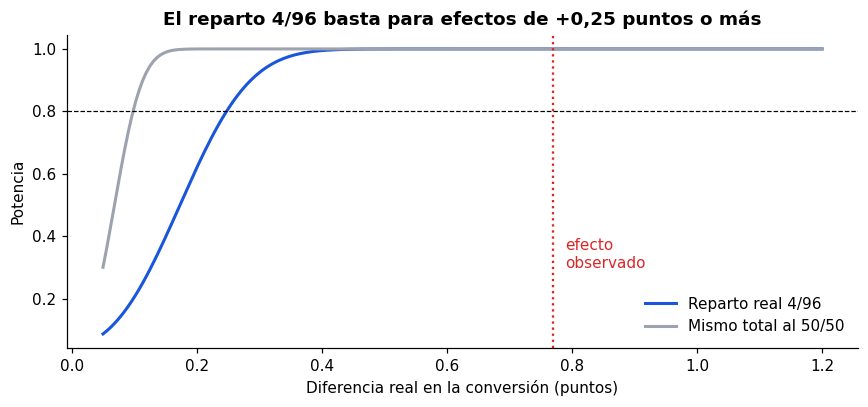

In [10]:
efectos = np.linspace(0.0005, 0.012, 200)
fig, ax = plt.subplots(figsize=(8, 3.8))
for (nombre, na, nb, color) in [("Reparto real 4/96", a.n, b.n, AZUL),
                                 ("Mismo total al 50/50", (a.n + b.n) // 2, (a.n + b.n) // 2, GRIS)]:
    ax.plot(100 * efectos, [potencia(a.tasa, e, na, nb) for e in efectos], label=nombre, color=color, lw=2)
ax.axhline(0.8, ls="--", color="black", lw=0.8)
ax.axvline(100 * r.diferencia, ls=":", color=ROJO)
ax.text(100 * r.diferencia + 0.02, 0.3, "efecto\nobservado", color=ROJO)
ax.set_xlabel("Diferencia real en la conversión (puntos)"); ax.set_ylabel("Potencia")
ax.set_title("El reparto 4/96 basta para efectos de +0,25 puntos o más")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(IMG + "potencia.png"); plt.show()

El experimento tenía potencia de sobra: detectaba efectos de +0,25 puntos (14 % relativo) y el observado es tres veces mayor.

El reparto 96/4 es una **decisión de negocio razonable**: dejar sin anuncios a pocos usuarios cuesta menos ventas mientras dura la prueba. El precio es precisión: con el mismo total al 50/50 el efecto mínimo detectable sería mucho menor. Si el efecto esperado fuera pequeño, este diseño se quedaría corto.

## 5. ¿Cuántas compras se deben a los anuncios?

Sin el experimento, la campaña se atribuiría las 14.423 compras del grupo con anuncios. Pero el control dice que **1,79 % de esos usuarios habría comprado igualmente**. Lo atribuible a los anuncios es solo la diferencia.

In [11]:
incrementales = b.n * r.diferencia
ic_inc = (b.n * r.ic_diferencia[0], b.n * r.ic_diferencia[1])
impresiones = anun["impresiones"].sum()
print(f"Compras del grupo anuncios: {b.conversiones:,}")
print(f"Compras incrementales:      {incrementales:,.0f}  (IC 95 %: {ic_inc[0]:,.0f} a {ic_inc[1]:,.0f})")
print(f"Parte atribuible a los anuncios: {incrementales / b.conversiones:.0%}")
print(f"Impresiones servidas: {impresiones:,}  ->  {1000 * incrementales / impresiones:.2f} compras extra cada 1.000 impresiones")

Compras del grupo anuncios: 14,423
Compras incrementales:      4,343  (IC 95 %: 3,360 a 5,326)
Parte atribuible a los anuncios: 30%
Impresiones servidas: 14,014,701  ->  0.31 compras extra cada 1.000 impresiones


Solo **~4.340 de las 14.423 compras (30 %)** se deben a los anuncios. El otro 70 % habría ocurrido sin ellos. Medir la campaña por las compras totales sobrevaloraría su efecto más de tres veces.

### ¿Cuánto se puede pagar por los anuncios?

El dataset no trae precios. Con el margen por compra como supuesto, el **CPM máximo rentable** (coste por 1.000 impresiones en el que la campaña ni gana ni pierde) es:

In [12]:
compras_por_mil = 1000 * incrementales / impresiones
pd.DataFrame({
    "margen_por_compra_eur": [10, 25, 50, 100],
}).assign(
    cpm_maximo_eur=lambda t: t["margen_por_compra_eur"] * compras_por_mil,
    cpm_maximo_pesimista_eur=lambda t: t["margen_por_compra_eur"] * 1000 * ic_inc[0] / impresiones,
).round(2)

,margen_por_compra_eur,cpm_maximo_eur,cpm_maximo_pesimista_eur
0,10,3.1000,2.4000
1,25,7.7500,5.9900
2,50,15.4900,11.9900
3,100,30.9900,23.9700


Con un margen de 50 € por compra, la campaña es rentable mientras el CPM no pase de ~15 € (~12 € en el escenario pesimista del intervalo).

## 6. ¿Para quién funcionan los anuncios?

El efecto medio esconde diferencias grandes. Comparo los grupos dentro de cada segmento. Como hago muchas comparaciones a la vez, ajusto los p-valores con **Holm** para no encontrar efectos por azar.

Las impresiones no las cambia el anuncio (los dos grupos ocupan el mismo hueco), así que comparar dentro de cada tramo es válido, y además corrige el pequeño desequilibrio del apartado 2. Lo que **no** se puede afirmar es que «ver más anuncios causa más efecto»: el número de impresiones no se asignó al azar, depende de lo activo que sea cada usuario.

In [13]:
tramos = efecto_por_segmento(df, "tramo_impresiones")
tramos["compras_incrementales"] = [
    (sub["grupo"] == "anuncios").sum() * fila.diferencia_pp / 100
    for (_, sub), fila in zip(df.groupby("tramo_impresiones", observed=True), tramos.itertuples())
]
tramos["pct_incrementales"] = tramos["compras_incrementales"] / tramos["compras_incrementales"].sum()
tramos

,tramo_impresiones,usuarios,pct_usuarios,conv_control,conv_anuncios,diferencia_pp,ic_bajo_pp,ic_alto_pp,lift,p_valor,p_holm,significativo,compras_incrementales,pct_incrementales
0,1-9,248910,0.4232,0.0038,0.0031,-0.0677,-0.1853,0.0500,-0.1790,0.2176,0.6527,False,-161.1020,-0.0368
1,10-24,173223,0.2945,0.0099,0.0095,-0.0457,-0.2975,0.2062,-0.0461,0.7164,1.0000,False,-76.3091,-0.0174
2,25-49,94874,0.1613,0.0251,0.0335,0.8364,0.3106,1.3622,0.3328,0.0061,0.0245,True,763.5655,0.1742
3,50-99,47625,0.0810,0.0553,0.1135,5.8199,4.7557,6.8840,1.0520,0.0000,0.0000,True,"2,660.2140",0.6070
4,100-199,17468,0.0297,0.1053,0.1774,7.2104,4.9647,9.4561,0.6845,0.0000,0.0000,True,"1,204.0676",0.2747
5,200 o más,6001,0.0102,0.1571,0.1557,-0.1339,-4.6471,4.3793,-0.0085,0.9535,1.0000,False,-7.6858,-0.0018


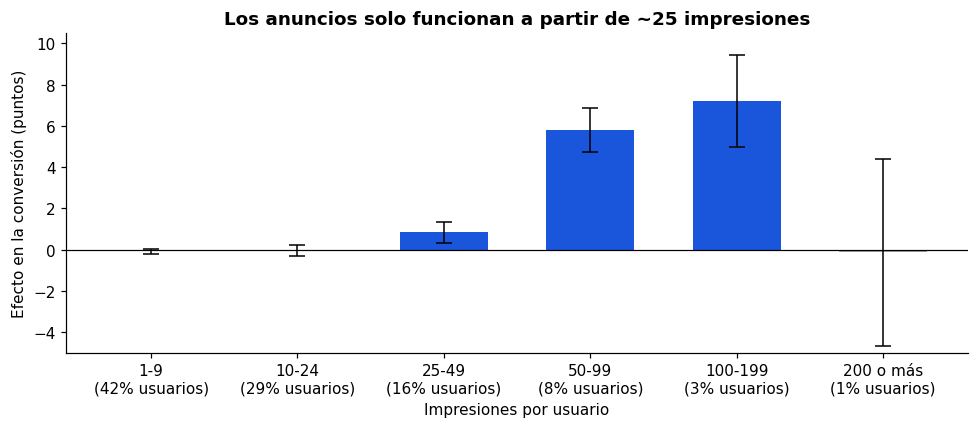

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(tramos))
colores = [AZUL if s else GRIS for s in tramos["significativo"]]
ax.bar(x, tramos["diferencia_pp"], color=colores, width=0.6)
ax.errorbar(x, tramos["diferencia_pp"],
            yerr=[tramos["diferencia_pp"] - tramos["ic_bajo_pp"], tramos["ic_alto_pp"] - tramos["diferencia_pp"]],
            fmt="none", ecolor="black", capsize=5, lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, [f"{t}\n({p:.0%} usuarios)" for t, p in zip(tramos["tramo_impresiones"], tramos["pct_usuarios"])])
ax.set_xlabel("Impresiones por usuario"); ax.set_ylabel("Efecto en la conversión (puntos)")
ax.set_ylim(-5, 10.5)
ax.set_title("Los anuncios solo funcionan a partir de ~25 impresiones")
fig.tight_layout(); fig.savefig(IMG + "efecto_por_impresiones.png"); plt.show()

Este es el hallazgo más útil del experimento:

- **Con menos de 25 impresiones (72 % de los usuarios) no hay efecto.** La diferencia es cero o incluso ligeramente negativa, sin significación.
- **De 25 a 199 impresiones (27 % de los usuarios) está todo el efecto:** entre +0,8 y +7,2 puntos. En el tramo de 50-99 los anuncios **doblan** la conversión.
- **Con 200 o más** el efecto desaparece: saturación (o usuarios que comprarían igualmente).

Casi todas las compras incrementales vienen del 27 % de usuarios con exposición media-alta.

In [15]:
dias = efecto_por_segmento(df, "dia_max")
franjas = efecto_por_segmento(df, "franja_horaria")
columnas = ["usuarios", "conv_control", "conv_anuncios", "diferencia_pp", "ic_bajo_pp", "ic_alto_pp", "p_holm", "significativo"]
display(dias.set_index("dia_max")[columnas])
display(franjas.set_index("franja_horaria")[columnas])

,usuarios,conv_control,conv_anuncios,diferencia_pp,ic_bajo_pp,ic_alto_pp,p_holm,significativo
dia_max,,,,,,,,
lunes,87073,0.0226,0.0332,1.0683,0.5617,1.5749,0.0025,True
martes,77479,0.0144,0.0304,1.5992,1.1483,2.0502,0.0000,True
miércoles,80908,0.0158,0.0254,0.9597,0.5319,1.3874,0.0023,True
jueves,82982,0.0202,0.0216,0.1407,-0.3124,0.5937,0.5548,False
viernes,92608,0.0163,0.0225,0.6162,0.2021,1.0303,0.0347,True
sábado,81660,0.0140,0.0213,0.7311,0.2888,1.1734,0.0299,True
domingo,85391,0.0206,0.0246,0.4025,-0.1118,0.9168,0.3144,False


,usuarios,conv_control,conv_anuncios,diferencia_pp,ic_bajo_pp,ic_alto_pp,p_holm,significativo
franja_horaria,,,,,,,,
madrugada (0-5 h),19837,0.0014,0.0135,1.2094,0.8968,1.5219,0.0045,True
mañana (6-11 h),142253,0.0126,0.0212,0.8589,0.5604,1.1574,0.0000,True
tarde (12-17 h),257839,0.0202,0.0277,0.7511,0.4796,1.0226,0.0000,True
noche (18-23 h),168172,0.0207,0.0274,0.6777,0.3134,1.0420,0.0027,True


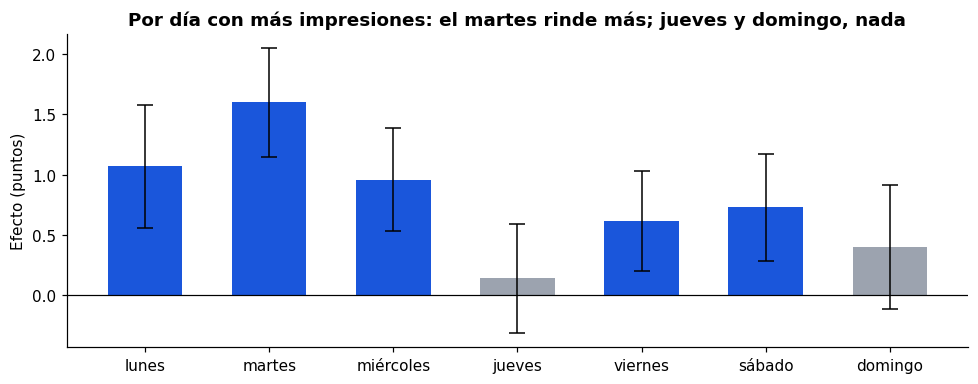

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.6))
colores = [AZUL if s else GRIS for s in dias["significativo"]]
ax.bar(dias["dia_max"].astype(str), dias["diferencia_pp"], color=colores, width=0.6)
ax.errorbar(range(len(dias)), dias["diferencia_pp"],
            yerr=[dias["diferencia_pp"] - dias["ic_bajo_pp"], dias["ic_alto_pp"] - dias["diferencia_pp"]],
            fmt="none", ecolor="black", capsize=5, lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Efecto (puntos)")
ax.set_title("Por día con más impresiones: el martes rinde más; jueves y domingo, nada")
fig.tight_layout(); fig.savefig(IMG + "efecto_por_dia.png"); plt.show()

Por día, el efecto es claro de lunes a miércoles (el martes, +1,6 puntos) y desaparece el jueves y el domingo. Por franja horaria es positivo en todas. La madrugada sale enorme en relativo, pero con muy pocas conversiones en el control (una), así que no hay que fiarse de ese número.

## 7. Conclusiones y recomendaciones

1. **La campaña funciona:** +0,77 puntos de conversión (+43 %, IC 95 % +30 % a +58 %). Tres métodos distintos coinciden y el resultado se mantiene al ajustar por el desequilibrio entre grupos.
2. **Solo el 30 % de las compras del grupo con anuncios se deben a ellos** (~4.340 de 14.423). Medir la campaña por compras totales la sobrevaloraría más de 3 veces.
3. **El efecto se concentra en usuarios con 25-199 impresiones.** Por debajo de 25 no hay efecto medible. Recomendación: **probar en un nuevo experimento** si dejar de mostrar anuncios a quien no llega a ese umbral (o subirles la frecuencia) ahorra presupuesto sin perder ventas. No se puede decidir solo con estos datos, porque las impresiones no se asignaron al azar.
4. **Concentrar presupuesto de lunes a miércoles** y probarlo también con un experimento.
5. **Usar el CPM máximo rentable** (~0,31 × margen por compra) como tope al comprar espacio publicitario.

## 8. Limitaciones

- Los grupos no están perfectamente equilibrados en impresiones y día. El efecto se mantiene al ajustar, pero no se sabe cómo se hizo la asignación.
- No hay fechas: no se puede ver si el efecto cambia con el tiempo (efecto novedad) ni cuánto duró la prueba.
- «Día» y «hora» son los de **más** impresiones, no los de la compra.
- Las impresiones dependen de la actividad del usuario, así que el análisis por tramos describe para quién funciona, no prueba que más impresiones causen más efecto.
- No hay importes: el impacto económico depende del margen por compra que se suponga.